# Exploratory Data Analysis

#### Objective

The objective is to predict the students' O-level mathematics examination score to help the school to identify weaker students prior to the examination using the dataset provided. In your submission, you should evaluate at least 3 suitable models for estimating the students' scores.

#### Overall Evaluation

Once you have identified the most suitable model, find a way to compare the models against each other and explain which of these models is more suitable for the task.

In [178]:
#import modules
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#load dataset
df = pd.read_csv('./data/regression_bonus_practice_data.csv')

df.head()

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


## 1. Preliminary Data Exploration

In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15900 entries, 0 to 15899
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               15900 non-null  int64  
 1   number_of_siblings  15900 non-null  int64  
 2   direct_admission    15900 non-null  object 
 3   CCA                 12071 non-null  object 
 4   learning_style      15900 non-null  object 
 5   student_id          15900 non-null  object 
 6   gender              15900 non-null  object 
 7   tuition             15900 non-null  object 
 8   final_test          15405 non-null  float64
 9   n_male              15900 non-null  float64
 10  n_female            15900 non-null  float64
 11  age                 15900 non-null  float64
 12  hours_per_week      15900 non-null  float64
 13  attendance_rate     15122 non-null  float64
 14  sleep_time          15900 non-null  object 
 15  wake_time           15900 non-null  object 
 16  mode

In [180]:
print(df.nunique())
print()
print("Check Categorical and Boolean Column unique values:")
print(f"{df.direct_admission.name}:{df.direct_admission.unique()}")
print(f"{df.CCA.name}:{df.CCA.unique()}")
print(f"{df.learning_style.name}:{df.learning_style.unique()}")
print(f"{df.gender.name}:{df.gender.unique()}")
print(f"{df.tuition.name}:{df.tuition.unique()}")
print(f"{df.mode_of_transport.name}:{df.mode_of_transport.unique()}")
print(f"{df.bag_color.name}:{df.bag_color.unique()}")

index                 15900
number_of_siblings        3
direct_admission          2
CCA                       7
learning_style            2
student_id            15000
gender                    2
tuition                   4
final_test               68
n_male                   32
n_female                 32
age                       6
hours_per_week           21
attendance_rate          61
sleep_time               13
wake_time                 5
mode_of_transport         3
bag_color                 6
dtype: int64

Check Categorical and Boolean Column unique values:
direct_admission:['Yes' 'No']
CCA:['Sports' nan 'Clubs' 'Arts' 'ARTS' 'SPORTS' 'CLUBS' 'NONE']
learning_style:['Visual' 'Auditory']
gender:['Female' 'Male']
tuition:['No' 'Yes' 'Y' 'N']
mode_of_transport:['private transport' 'public transport' 'walk']
bag_color:['yellow' 'green' 'white' 'red' 'blue' 'black']


In [181]:
df.describe()

,index,number_of_siblings,final_test,n_male,n_female,age,hours_per_week,attendance_rate
count,15900.000000,15900.000000,15405.000000,15900.000000,15900.000000,15900.000000,15900.000000,15122.000000
mean,7949.500000,0.886541,67.165401,13.880000,8.906038,15.213459,10.312579,93.270268
std,4590.078975,0.751346,13.977879,6.552584,6.663852,1.758941,4.461861,7.984230
min,0.000000,0.000000,32.000000,0.000000,0.000000,-5.000000,0.000000,40.000000
25%,3974.750000,0.000000,56.000000,10.000000,4.000000,15.000000,7.000000,92.000000
50%,7949.500000,1.000000,68.000000,14.000000,8.000000,15.000000,9.000000,95.000000
75%,11924.250000,1.000000,78.000000,18.000000,13.000000,16.000000,14.000000,97.000000
max,15899.000000,2.000000,100.000000,31.000000,31.000000,16.000000,20.000000,100.000000


In [182]:
df.shape

(15900, 18)

In [183]:
df.isnull().sum()

index                    0
number_of_siblings       0
direct_admission         0
CCA                   3829
learning_style           0
student_id               0
gender                   0
tuition                  0
final_test             495
n_male                   0
n_female                 0
age                      0
hours_per_week           0
attendance_rate        778
sleep_time               0
wake_time                0
mode_of_transport        0
bag_color                0
dtype: int64

In [184]:
print(f"Student IDs duplicated: {df['student_id'].duplicated().sum()}")
duplicated_df = df[df["student_id"].duplicated(keep=False)].sort_values(by="student_id")
duplicated_df.head(25)

Student IDs duplicated: 900


,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
5534,5534,0,No,Clubs,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,green
12290,12290,0,No,Clubs,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,white
12270,12270,1,No,Arts,Visual,0195IO,Female,No,52.0,8.0,22.0,16.0,15.0,99.0,22:00,6:00,private transport,yellow
13541,13541,1,No,Arts,Visual,0195IO,Female,No,52.0,8.0,22.0,16.0,15.0,99.0,22:00,6:00,private transport,yellow
4303,4303,0,No,Clubs,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,yellow
9172,9172,0,No,Clubs,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,green
8641,8641,0,No,Arts,Auditory,0FC4RY,Female,No,68.0,23.0,4.0,15.0,6.0,NaN,23:00,7:00,walk,blue
9791,9791,0,No,Arts,Auditory,0FC4RY,Female,No,68.0,23.0,4.0,15.0,6.0,100.0,23:00,7:00,walk,yellow
1405,1405,0,Yes,NaN,Visual,0JUGAF,Female,No,84.0,18.0,2.0,16.0,10.0,94.0,23:00,7:00,walk,red
6339,6339,0,Yes,NaN,Visual,0JUGAF,Female,No,84.0,18.0,2.0,16.0,10.0,94.0,23:00,7:00,walk,yellow


#### Initial observations and interpretations based on basic data overview:
* The dataset has 15900 rows and 18 columns.
* student_id is the primary key for this dataset. It requires cleanup due to presence of duplicate student_id.
* There is no datetime entry for the dataset, we will assume order of data entry to be by index number. This means bigger index numbers will contain the newer information and we will use keep last entry.
* There are null values for CCA, final_test and attendance_rate. For CCA as it is categorical, null would be assumed as having no CCA and would be a categorised as None. For final_test we will need to drop the row if it is still null after data cleaning and preprocessing as we are predicting final_test scores and this column will be required as the target value. For attendance_rate, if is null, we will give the average based on data that has the same hours_per_week.
* Multiple data types for columns are reflected as objects, we will need to handle it to convert them to numerical or parse them as the correct type.

## 2. Univariate Analysis

#### Data cleaning

In [185]:
# Drop student id duplicates, opting to keep the assumed latest entry by using keep="last"
df_cleaned = df.sort_index()
df_cleaned = df.drop_duplicates(subset="student_id", keep="last")
df_cleaned.shape

# Fix NaN values
df_cleaned["CCA"].fillna("None", inplace=True)
# For attendance_rate, we can fill NaN values with the average attendance rate for students with similar hours_per_week
avg_attendance_by_hours = df.groupby('hours_per_week')['attendance_rate'].transform('mean')
df['attendance_rate'] = df['attendance_rate'].fillna(avg_attendance_by_hours)

# Fix inconsistent categorical/boolean values for CCA and tuition columns
df_cleaned['CCA'] = df_cleaned['CCA'].replace({'ARTS': 'Arts', 'SPORTS': 'Sports', 'CLUBS': 'Clubs', 'NONE': 'None'})
df_cleaned['tuition'] = df_cleaned['tuition'].replace({'Y': 'Yes', 'N': 'No'})

# Drop final_test_score rows with NaN values
df_cleaned.dropna(subset=["final_test"], inplace=True)
df_cleaned.describe()

/var/folders/sp/64pcmd2d017g7380v7snsn640000gn/T/ipykernel_38352/505332363.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_cleaned["CCA"].fillna("None", inplace=True)
/var/folders/sp/64pcmd2d017g7380v7snsn640000gn/T/ipykernel_38352/505332363.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned["CCA"].fillna("None", inplace=Tru

,index,number_of_siblings,final_test,n_male,n_female,age,hours_per_week,attendance_rate
count,14529.000000,14529.000000,14529.000000,14529.000000,14529.000000,14529.000000,14529.000000,13816.000000
mean,8103.908184,0.888637,67.199463,13.861587,8.914516,15.208755,10.322527,93.282571
std,4587.252155,0.752008,13.978261,6.548104,6.659316,1.775341,4.462341,7.946595
min,0.000000,0.000000,32.000000,0.000000,0.000000,-5.000000,0.000000,40.000000
25%,4158.000000,0.000000,56.000000,10.000000,4.000000,15.000000,7.000000,92.000000
50%,8172.000000,1.000000,68.000000,14.000000,8.000000,15.000000,9.000000,95.000000
75%,12097.000000,1.000000,78.000000,18.000000,13.000000,16.000000,14.000000,97.000000
max,15899.000000,2.000000,100.000000,31.000000,31.000000,16.000000,20.000000,100.000000


#### Visualising Distributions

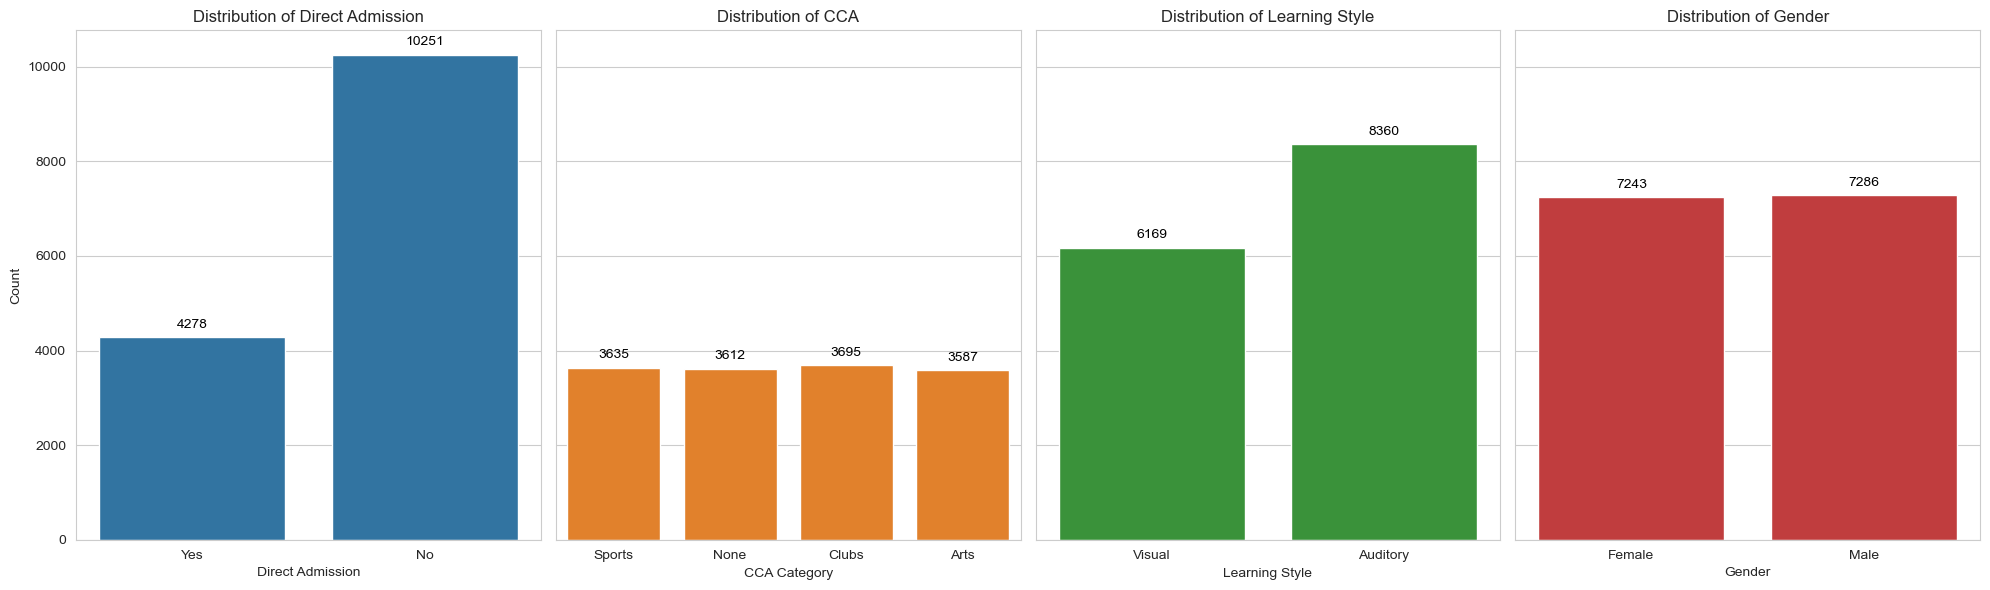

In [ ]:
# Set the style
sns.set_style('whitegrid')

# Create figure
fig, axes = plt.subplots(1, 4, figsize=(20, 6), sharey=True)

# Direct Admission Count
plot1 = sns.countplot(data=df_cleaned, x="direct_admission", ax=axes[0], color="tab:blue")
axes[0].set_title("Distribution of Direct Admission", fontsize=12)
axes[0].set_xlabel("Direct Admission")
axes[0].set_ylabel("Count")

# CCA Count
plot2 = sns.countplot(data=df_cleaned, x="CCA", ax=axes[1], color="tab:orange")
axes[1].set_title("Distribution of CCA", fontsize=12)
axes[1].set_xlabel("CCA Category")
axes[1].set_ylabel("") # Hide middle y-label

# Learning Style Count
plot3 = sns.countplot(data=df_cleaned, x="learning_style", ax=axes[2], color="tab:green")
axes[2].set_title("Distribution of Learning Style", fontsize=12)
axes[2].set_xlabel("Learning Style")
axes[2].set_ylabel("") 

# Gender Count
plot4 = sns.countplot(data=df_cleaned, x="gender", ax=axes[3], color="tab:red")
axes[3].set_title("Distribution of Gender", fontsize=12)
axes[3].set_xlabel("Gender")
axes[3].set_ylabel("") 

# Add annotations to all subplots
for ax in axes:
    for p in ax.patches:
        count = int(p.get_height())
        ax.annotate(f'{count}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', fontsize=10, color='black', xytext=(0, 9),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

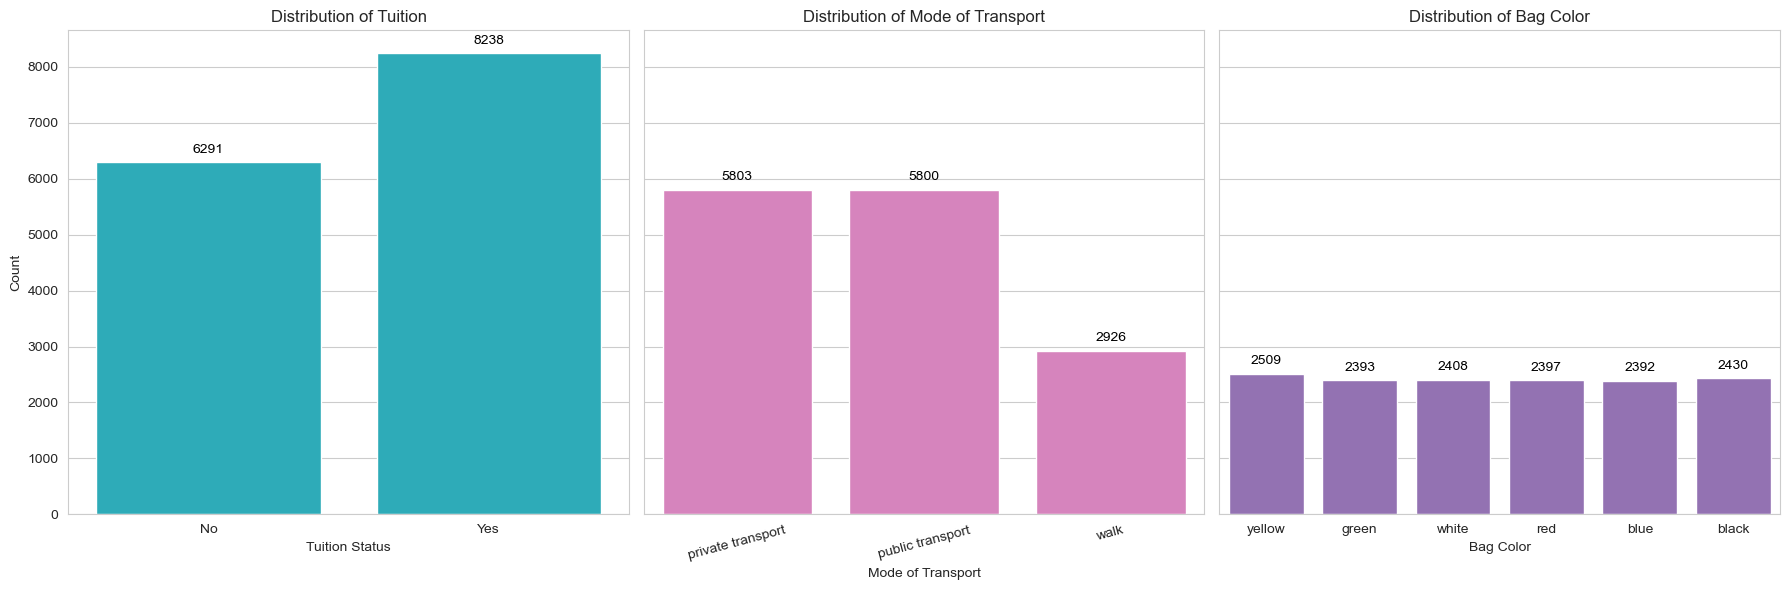

In [220]:
# Set the style
sns.set_style('whitegrid')

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Tuition Count
plot5 = sns.countplot(data=df_cleaned, x="tuition", ax=axes[0], color="tab:cyan")
axes[0].set_title("Distribution of Tuition", fontsize=12)
axes[0].set_xlabel("Tuition Status")
axes[0].set_ylabel("Count")

# Mode of Transport Count
plot6 = sns.countplot(data=df_cleaned, x="mode_of_transport", ax=axes[1], color="tab:pink")
axes[1].set_title("Distribution of Mode of Transport", fontsize=12)
axes[1].set_xlabel("Mode of Transport")
axes[1].set_ylabel("") 
axes[1].tick_params(axis='x', rotation=15) # Slight tilt if text labels overlap

# Bag Color Count
plot7 = sns.countplot(data=df_cleaned, x="bag_color", ax=axes[2], color="tab:purple")
axes[2].set_title("Distribution of Bag Color", fontsize=12)
axes[2].set_xlabel("Bag Color")
axes[2].set_ylabel("") 

# Add annotations to all subplots
for ax in axes:
    for p in ax.patches:
        count = int(p.get_height())
        ax.annotate(f'{count}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', fontsize=10, color='black', xytext=(0, 9),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

Trends:

Significant Class Imbalances: 
* We see a heavy skew toward students who did not enter via direct admission, with the "No" group ($10,251$) being more than double the size of the "Yes" group ($4,278$). 
* "Auditory" learners ($8,360$) are noticeably more common than "Visual" learners ($6,169$), 
* A larger majority of students attend tuition, "Yes" ($8,238$) compared to those who do not, "No" ($6,291$). 
* For transport, "private transport" ($5,803$) and "public transport" ($5,800$) are equally dominant, while those who "walk" ($2,926$) make up exactly half of either group.

Highly Uniform Distributions: 
* The dataset is incredibly well-balanced between "Female" ($7,243$) and "Male" ($7,286$) students.
* The four choices in CCA are uniformly distributed, hovering right around ($3,600$) students each
* All six Bag Color variations display a flat distribution ranging tightly between ($2,383$) and ($2,509$) instances.

Sample sizes are large enough to eliminate random sampling bias, making observed trends reflective of the broader student population.

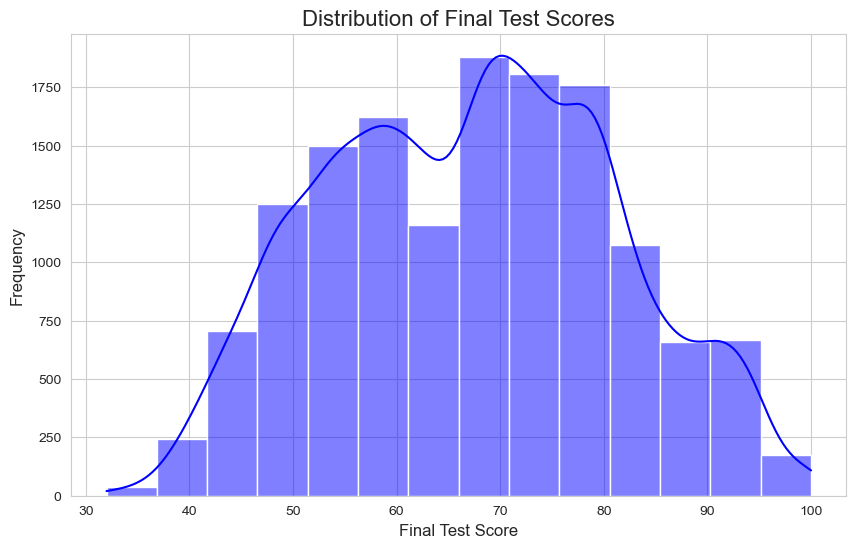

In [187]:
# draw histogram to display the final_test scores distribution
sns.set_style('whitegrid')

#histogram for final_test distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_cleaned['final_test'], bins=14, kde=True, color='blue') #14 bins from 30 to 100 with increments of 5
plt.title('Distribution of Final Test Scores', fontsize=16)
plt.xlabel('Final Test Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

Interpreting the histogram
In the histogram we plotted above, we can make several key observations about the 'final_test' target variable we aim to predict:

1. Central Tendency and Distribution

The histogram shows that most frequent counts of final_test in the dataset cluster around a central range. The mean final_test is approximately 67.2, and the median is 68. This indicates that half of the students have final_test below 68, and half are above. These values were obtained using df.describe() after removing duplicates.

2. Variability and Spread

The final_test vary widely, as indicated by the standard deviation of about 14.0. The final_test scores range from a minimum of 32 to a maximum of 100, showing a broad spectrum of final_test scores.

3. Peaks and Common Prices

The most common final_test (mode) is 65-70 bucket, which is where the highest peak of the histogram lies. This final_test score is the most frequent among the properties in the dataset.

4. Skewness

The distribution follows a normal distribution pattern, characterized by symmetry around the mean. Most values cluster near the center, with decreasing frequency as values move toward the tails on both sides.


## 3. Bivariate Analysis

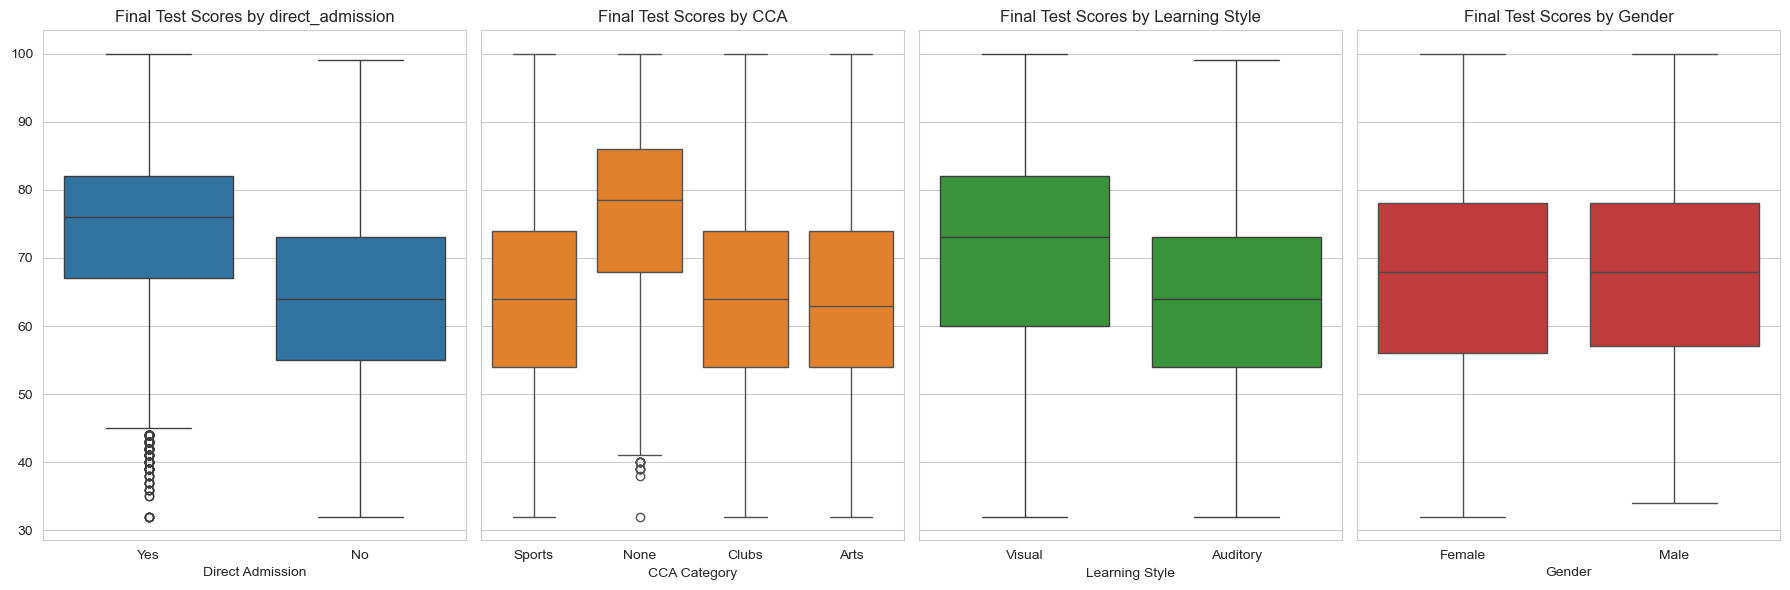

In [216]:
# Create side-by-side box plots for categorical features vs final_text scores
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

# Plot Direct Admission
sns.boxplot(
    data=df_cleaned, 
    x="direct_admission", 
    y="final_test", 
    ax=axes[0],
    color="tab:blue"
)
axes[0].set_title("Final Test Scores by direct_admission")
axes[0].set_xlabel("Direct Admission")
axes[0].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot CCA
sns.boxplot(
    data=df_cleaned, 
    x="CCA", 
    y="final_test", 
    ax=axes[1],
    color="tab:orange"
)
axes[1].set_title("Final Test Scores by CCA")
axes[1].set_xlabel("CCA Category")
axes[1].set_ylabel("Final Test Score") # This label will show on the far left

# Plot Learning Style
sns.boxplot(
    data=df_cleaned, 
    x="learning_style", 
    y="final_test", 
    ax=axes[2],
    color="tab:green"
)
axes[2].set_title("Final Test Scores by Learning Style")
axes[2].set_xlabel("Learning Style")
axes[2].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot tuition
sns.boxplot(
    data=df_cleaned, 
    x="gender", 
    y="final_test", 
    ax=axes[3],
    color="tab:red"
)
axes[3].set_title("Final Test Scores by Gender")
axes[3].set_xlabel("Gender")
axes[3].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis


# 4. Clean up the spacing and render
plt.tight_layout()
plt.show()

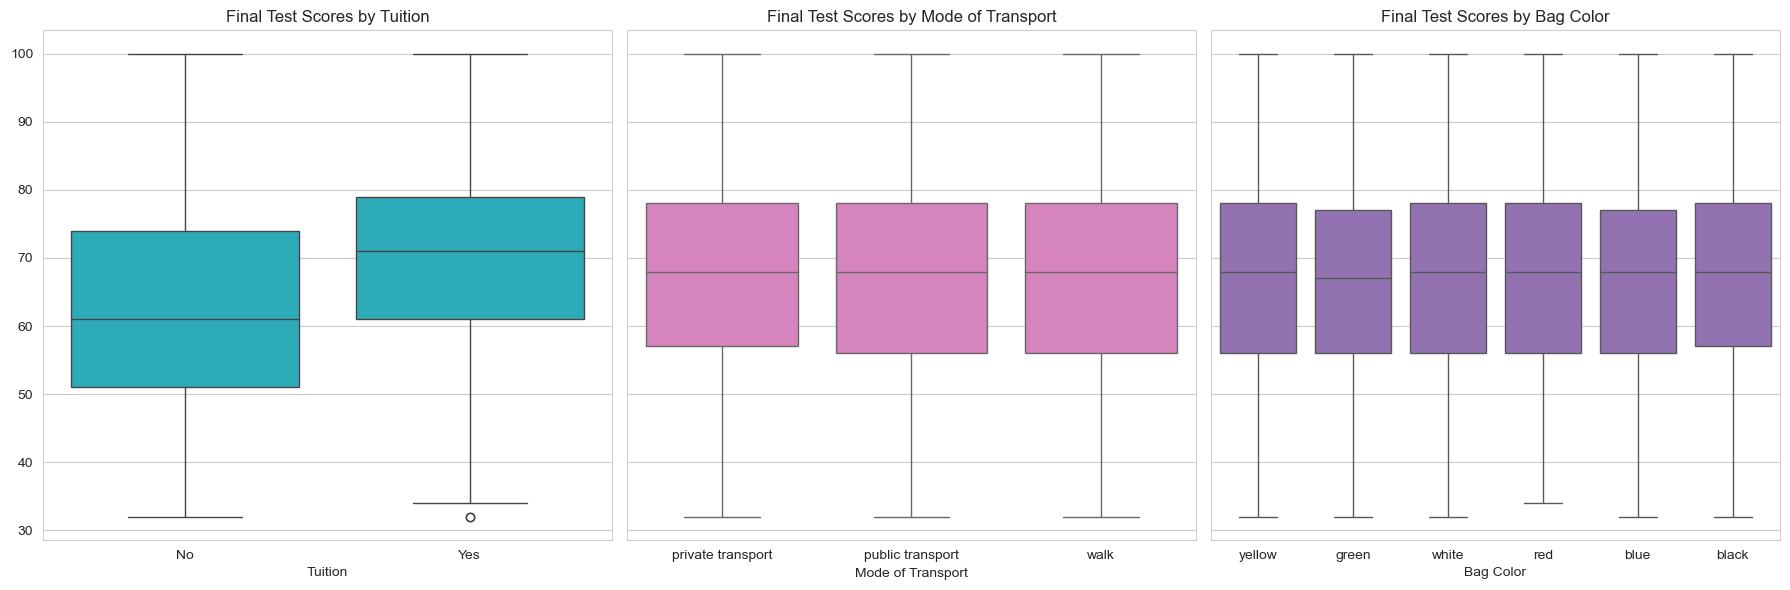

In [218]:
# Create side-by-side box plots for categorical features vs final_text scores
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Plot tuition
sns.boxplot(
    data=df_cleaned, 
    x="tuition", 
    y="final_test", 
    ax=axes[0],
    color="tab:cyan"
)
axes[0].set_title("Final Test Scores by Tuition")
axes[0].set_xlabel("Tuition")
axes[0].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis


# Plot mode of transport
sns.boxplot(
    data=df_cleaned, 
    x="mode_of_transport", 
    y="final_test", 
    ax=axes[1],
    color="tab:pink"
)
axes[1].set_title("Final Test Scores by Mode of Transport")
axes[1].set_xlabel("Mode of Transport")
axes[1].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis



# Plot bag color
sns.boxplot(
    data=df_cleaned, 
    x="bag_color", 
    y="final_test", 
    ax=axes[2],
    color="tab:purple"
)
axes[2].set_title("Final Test Scores by Bag Color")
axes[2].set_xlabel("Bag Color")
axes[2].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis


# 4. Clean up the spacing and render
plt.tight_layout()
plt.show()

Interpreting box pLot for categorical variables
In the two sets of box plots we have plotted above, we can make several key observations about the relationship between each categorical and 'final_test' features.

Commentary on Key Predictors of Final Test Scores:
Direct admission, CCA, learning style and tuition show differentiated final test scores statistically and may be key predictors of final test scores.

1. Final Test Score Distribution

The final test score distribution spread shows that when studects enter through direct admission or have no CCA, the spread is smaller as the bottom quartile values are higher then their counter parts. Males and students with tuition have marginally smaller spread for final test scores compared to their counter parts. 

2. Median Test Score

The following feature and value pairs show significant higher median values than other options in their respective categories:
* direct_admission: "Yes" has a higher median than "No"
* CCA: "None" has a higher median than "Sports", "Clubs" and "Arts"
* learning_style: "Visual" has a higher median than "Auditory"
* tuition: "Yes" has a higher median than "No"
Students with these feature values are likely to achieve better final test scores. Students with no CCA achieve the highest median score when compared against other categorical features.


3. Interquartile Range (IQR)

The IQR, which is the range between the 25th and 75th percentiles, is slightly narrower for the following feature and value pairs:
* direct_admission: "Yes" has a narrower IQR than "No"
* CCA: "None" has a narrower IQR than "Sports", "Clubs" and "Arts"
* tuition: "Yes" has a narrower IQR than "No"
Students with these feature values are performing more consistently with tighter range of final_test scores for the IQR.

4. Outliers

There is the presence of outliers in the final test scores for direct_admissions, CCA and tuition. These outliers represent final test scores that deviate significantly from the general score trend, possibly due to other factors.


Commentary on Non-impactful indicators of Final Test Scores:
Gender, Mode of Transport, and Bag Color show uniform distributions. The medians and IQRs are almost identical across all variations, meaning these factors hold no observed statistical relationship with a student's final test score.
